In [ ]:
import sys
!"{sys.executable}" -m pip install qiskit qiskit-aer

# Projeto C1 — Simulador de qubit do zero
Computação Quântica · FAESA · 2026/2

In [21]:
import sys, site
pasta = site.getusersitepackages()
if pasta not in sys.path:
    sys.path.append(pasta)

In [2]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)  # semente fixa: resultados reproduzíveis

## Parte A — Núcleo do simulador

In [24]:
def estado(alpha, beta):
    """Recebe duas amplitudes complexas e devolve o vetor de estado normalizado."""
    psi = np.array([alpha, beta], dtype=complex)
    n = np.sqrt(np.sum(np.abs(psi)**2))
    if n < 1e-12:
        raise ValueError("Vetor nulo não representa um estado quântico e não pode ser normalizado.")
    return psi / n

def norma(psi):
    """Devolve sqrt(<psi|psi>)."""
    return np.sqrt(np.vdot(psi, psi).real)   # vdot já conjuga o primeiro vetor

def aplicar(U, psi, tol=1e-10):
    """Aplica U ao estado, mas só se U for unitário (U†U = I)."""
    U = np.asarray(U, dtype=complex)
    if not np.allclose(U.conj().T @ U, np.eye(2), atol=tol):
        raise ValueError("Operador recusado: não é unitário (U†U ≠ I).")
    return U @ psi

def probabilidades(psi):
    """Devolve (|alpha|², |beta|²)."""
    p = np.abs(psi)**2
    return p[0], p[1]

H = np.array([[1, 1], [1, -1]]) / np.sqrt(2)
ket0 = estado(1, 0)

In [26]:
# Validação com a tabela do enunciado
testes = {
    "3|0> + 4|1>":         estado(3, 4),
    "(1+i)|0> + (1-i)|1>": estado(1+1j, 1-1j),
    "H|0>":                aplicar(H, ket0),
}
for nome, psi in testes.items():
    p0, p1 = probabilidades(psi)
    print(f"{nome:22s} amplitudes = {np.round(psi, 4)}   (p0, p1) = ({p0:.4f}, {p1:.4f})")

3|0> + 4|1>            amplitudes = [0.6+0.j 0.8+0.j]   (p0, p1) = (0.3600, 0.6400)
(1+i)|0> + (1-i)|1>    amplitudes = [0.5+0.5j 0.5-0.5j]   (p0, p1) = (0.5000, 0.5000)
H|0>                   amplitudes = [0.7071+0.j 0.7071+0.j]   (p0, p1) = (0.5000, 0.5000)


In [5]:
# Conservação da norma
psi = estado(0.6, 0.8)
print("Norma antes de H :", norma(psi))
print("Norma depois de H:", norma(aplicar(H, psi)))

# Recusa de operador não unitário
M = np.array([[1, 1], [0, 1]])
try:
    aplicar(M, psi)
except ValueError as e:
    print("Erro esperado:", e)

# O que aconteceria sem a verificação:
errado = M @ psi
print("Sem verificação, 'probabilidades' =", np.abs(errado)**2, "soma =", np.sum(np.abs(errado)**2))

# Recusa do vetor nulo
try:
    estado(0, 0)
except ValueError as e:
    print("Erro esperado:", e)

Norma antes de H : 1.0
Norma depois de H: 0.9999999999999999
Erro esperado: Operador recusado: não é unitário (U†U ≠ I).
Sem verificação, 'probabilidades' = [1.96 0.64] soma = 2.5999999999999996
Erro esperado: Vetor nulo não representa um estado quântico e não pode ser normalizado.


## Parte B — Medição, colapso e amostragem

In [6]:
def medir(psi):
    """Sorteia 0 ou 1 pela regra de Born e devolve (resultado, estado após a medição)."""
    p0, _ = probabilidades(psi)
    resultado = 0 if rng.random() < p0 else 1
    colapsado = estado(1, 0) if resultado == 0 else estado(0, 1)
    return resultado, colapsado

def amostrar(psi, N):
    """Mede N vezes o estado ORIGINAL e devolve a contagem de cada resultado."""
    contagem = {0: 0, 1: 0}
    for _ in range(N):
        r, _ = medir(psi)   # sempre sobre psi, não sobre o colapsado
        contagem[r] += 1
    return contagem

In [7]:
# Experimento B1 — colapso
psi = estado(0.6, 0.8)
r, pos = medir(psi)
seq = [r]
for _ in range(10):
    r2, pos = medir(pos)
    seq.append(r2)
print("Primeira medição:", seq[0])
print("Dez medições seguintes:", seq[1:])

Primeira medição: 1
Dez medições seguintes: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


       N |    f(0) |    f(1) |   desvio | 0.48/sqrt(N)
     100 |  0.3500 |  0.6500 |  0.01000 |      0.04800
    1000 |  0.3620 |  0.6380 |  0.00200 |      0.01518
   10000 |  0.3610 |  0.6390 |  0.00100 |      0.00480
  100000 |  0.3585 |  0.6415 |  0.00154 |      0.00152


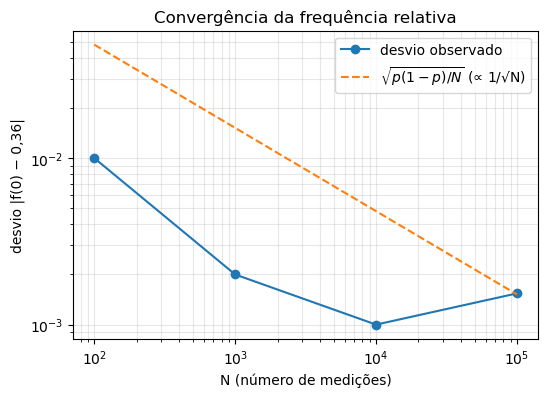

In [8]:
# Experimento B2 — convergência
p0_teo, p1_teo = probabilidades(psi)
Ns = [100, 1_000, 10_000, 100_000]
desvios = []
print(f"{'N':>8} | {'f(0)':>7} | {'f(1)':>7} | {'desvio':>8} | {'0.48/sqrt(N)':>12}")
for N in Ns:
    c = amostrar(psi, N)
    f0, f1 = c[0]/N, c[1]/N
    d = abs(f0 - p0_teo)          # |f1 - p1| é o mesmo valor
    desvios.append(d)
    print(f"{N:>8} | {f0:7.4f} | {f1:7.4f} | {d:8.5f} | {np.sqrt(p0_teo*p1_teo/N):12.5f}")

plt.figure(figsize=(6, 4))
plt.loglog(Ns, desvios, "o-", label="desvio observado")
plt.loglog(Ns, [np.sqrt(p0_teo*p1_teo/N) for N in Ns], "--", label=r"$\sqrt{p(1-p)/N}$ (∝ 1/√N)")
plt.xlabel("N (número de medições)"); plt.ylabel("desvio |f(0) − 0,36|")
plt.title("Convergência da frequência relativa"); plt.legend(); plt.grid(True, which="both", alpha=.3)
plt.show()

## Parte C — Esfera de Bloch, fase global e fase relativa

In [9]:
def bloch(psi):
    """Coordenadas (x, y, z) do estado na esfera de Bloch."""
    a, b = psi
    ab = np.conj(a) * b
    x = 2 * ab.real
    y = 2 * ab.imag
    z = abs(a)**2 - abs(b)**2
    return np.round(np.array([x, y, z]), 10)

s = 1/np.sqrt(2)
tabela = {
    "|0>":           estado(1, 0),
    "|1>":           estado(0, 1),
    "|+>":           estado(s, s),
    "|->":           estado(s, -s),
    "(|0>+i|1>)/√2": estado(s, 1j*s),
    "0.6|0>+0.8|1>": estado(0.6, 0.8),
}
for nome, psi in tabela.items():
    print(f"{nome:15s} -> {bloch(psi)}")

|0>             -> [0. 0. 1.]
|1>             -> [ 0.  0. -1.]
|+>             -> [1. 0. 0.]
|->             -> [-1.  0.  0.]
(|0>+i|1>)/√2   -> [0. 1. 0.]
0.6|0>+0.8|1>   -> [ 0.96  0.   -0.28]


In [10]:
# Experimento C1 — fase global
psi = estado(0.6, 0.8)
psi_fase = np.exp(1j*np.pi/3) * psi
print("Original      : amplitudes", np.round(psi, 4), "prob", np.round(probabilidades(psi), 4), "Bloch", bloch(psi))
print("Com e^(iπ/3)  : amplitudes", np.round(psi_fase, 4), "prob", np.round(probabilidades(psi_fase), 4), "Bloch", bloch(psi_fase))

Original      : amplitudes [0.6+0.j 0.8+0.j] prob [0.36 0.64] Bloch [ 0.96  0.   -0.28]
Com e^(iπ/3)  : amplitudes [0.3+0.5196j 0.4+0.6928j] prob [0.36 0.64] Bloch [ 0.96 -0.   -0.28]


In [11]:
# Experimento C2 — fase relativa
mais, menos = estado(s, s), estado(s, -s)
print("Antes de H:  |+> ->", np.round(probabilidades(mais), 4), "  |-> ->", np.round(probabilidades(menos), 4))
print("Depois de H: H|+> ->", np.round(probabilidades(aplicar(H, mais)), 4), " H|-> ->", np.round(probabilidades(aplicar(H, menos)), 4))

Antes de H:  |+> -> [0.5 0.5]   |-> -> [0.5 0.5]
Depois de H: H|+> -> [1. 0.]  H|-> -> [0. 1.]


## Parte D — Os mesmos experimentos em Qiskit

In [22]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

sim = AerSimulator()
SHOTS = 4096

def rodar_qiskit(qc):
    counts = sim.run(transpile(qc, sim), shots=SHOTS).result().get_counts()
    return {0: counts.get("0", 0), 1: counts.get("1", 0)}   # Qiskit usa strings como chave

# 1) 0.6|0> + 0.8|1> com initialize
qc1 = QuantumCircuit(1, 1)
qc1.initialize([0.6, 0.8], 0)
qc1.measure(0, 0)

# 2) H|0> com a porta h
qc2 = QuantumCircuit(1, 1)
qc2.h(0)
qc2.measure(0, 0)

resultados = {
    "0,6|0> + 0,8|1>": (amostrar(estado(0.6, 0.8), SHOTS), rodar_qiskit(qc1), (0.36, 0.64)),
    "H|0>":            (amostrar(aplicar(H, ket0), SHOTS), rodar_qiskit(qc2), (0.5, 0.5)),
}
for nome, (meu, qk, p) in resultados.items():
    dp = np.sqrt(SHOTS * p[0] * p[1])
    print(f"{nome}: meu = {meu}  Qiskit = {qk}  esperado = {[round(SHOTS*x) for x in p]}  (desvio-padrão ≈ {dp:.1f})")

0,6|0> + 0,8|1>: meu = {0: 1489, 1: 2607}  Qiskit = {0: 1472, 1: 2624}  esperado = [1475, 2621]  (desvio-padrão ≈ 30.7)
H|0>: meu = {0: 2059, 1: 2037}  Qiskit = {0: 2035, 1: 2061}  esperado = [2048, 2048]  (desvio-padrão ≈ 32.0)


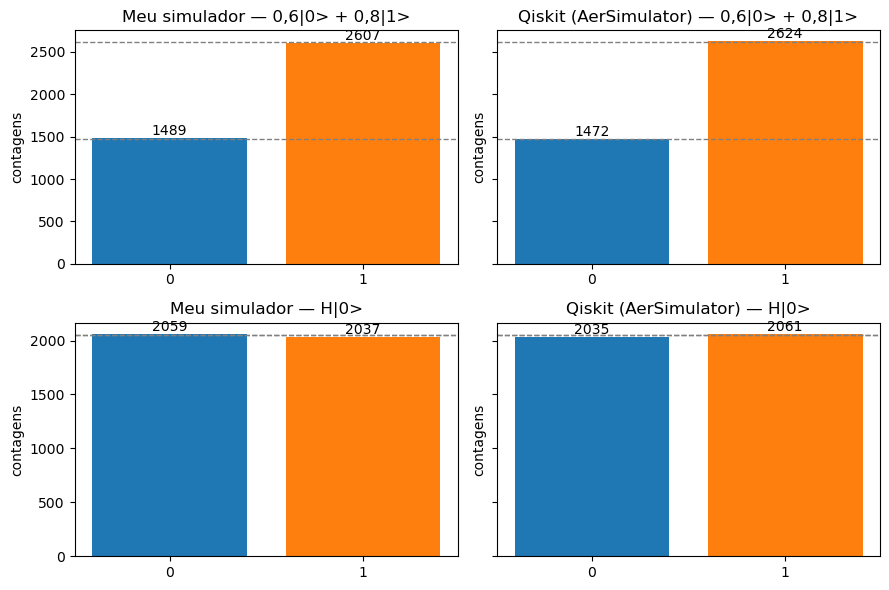

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(9, 6), sharey="row")
for i, (nome, (meu, qk, p)) in enumerate(resultados.items()):
    for j, (titulo, c) in enumerate([("Meu simulador", meu), ("Qiskit (AerSimulator)", qk)]):
        ax = axes[i, j]
        ax.bar(["0", "1"], [c[0], c[1]], color=["tab:blue", "tab:orange"])
        ax.axhline(SHOTS*p[0], ls="--", c="gray", lw=1)
        ax.axhline(SHOTS*p[1], ls="--", c="gray", lw=1)
        for k in (0, 1):
            ax.text(k, c[k], str(c[k]), ha="center", va="bottom")
        ax.set_title(f"{titulo} — {nome}")
        ax.set_ylabel("contagens")
plt.tight_layout(); plt.show()